Johannes Standhal og Rozalia Ciupka

# CA5

### Imports

In [126]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer

# Pipelines and dimension reduction
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Models
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model selection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold

# Evaluation
from sklearn.metrics import mean_absolute_error

### Reading data

In [127]:
df_train = pd.read_csv("train.csv")
df_submission = pd.read_csv("test.csv")

### Data exploration and visualisation

In [128]:
df_train.info()

categorical = ['smoking_status']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367500 entries, 0 to 367499
Data columns (total 17 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            367500 non-null  int64  
 1   age                           345653 non-null  float64
 2   sleep_duration_hrs            340323 non-null  float64
 3   sleep_quality_score           357702 non-null  float64
 4   cardio_mins_wk                355386 non-null  float64
 5   water_intake_liters           358969 non-null  float64
 6   screen_time_recreational_hrs  338865 non-null  float64
 7   social_media_hrs              362207 non-null  float64
 8   blood_pressure_sys            357789 non-null  float64
 9   diet_ultra_processed_pct      354171 non-null  float64
 10  diet_omega3_freq              344987 non-null  float64
 11  smoking_status                342146 non-null  object 
 12  alcohol_drinks_wk             346938 non-nul

In [129]:
# Check for missing values
print(f"missing values in training data: {df_train.isna().sum()}\n")

print(f"Total missing values in training data: {df_train.isna().sum().sum()}")

missing values in training data: id                                  0
age                             21847
sleep_duration_hrs              27177
sleep_quality_score              9798
cardio_mins_wk                  12114
water_intake_liters              8531
screen_time_recreational_hrs    28635
social_media_hrs                 5293
blood_pressure_sys               9711
diet_ultra_processed_pct        13329
diet_omega3_freq                22513
smoking_status                  25354
alcohol_drinks_wk               20562
novel_learning_hrs_wk           26727
social_connection_score         24873
chronic_stress_score            17929
target                              0
dtype: int64

Total missing values in training data: 274393


In [130]:
# Check for duplicate rows, we have none
print("Duplicate rows:", df_train.duplicated().sum())

Duplicate rows: 0


In [131]:
# Class distribution in the training data
print(df_train["target"].value_counts(normalize=True))


target
30    0.229078
28    0.199118
27    0.177810
29    0.167312
26    0.120332
25    0.062846
24    0.026590
23    0.010397
22    0.004101
21    0.001480
20    0.000661
19    0.000196
18    0.000073
17    0.000005
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Correlation map from training data')

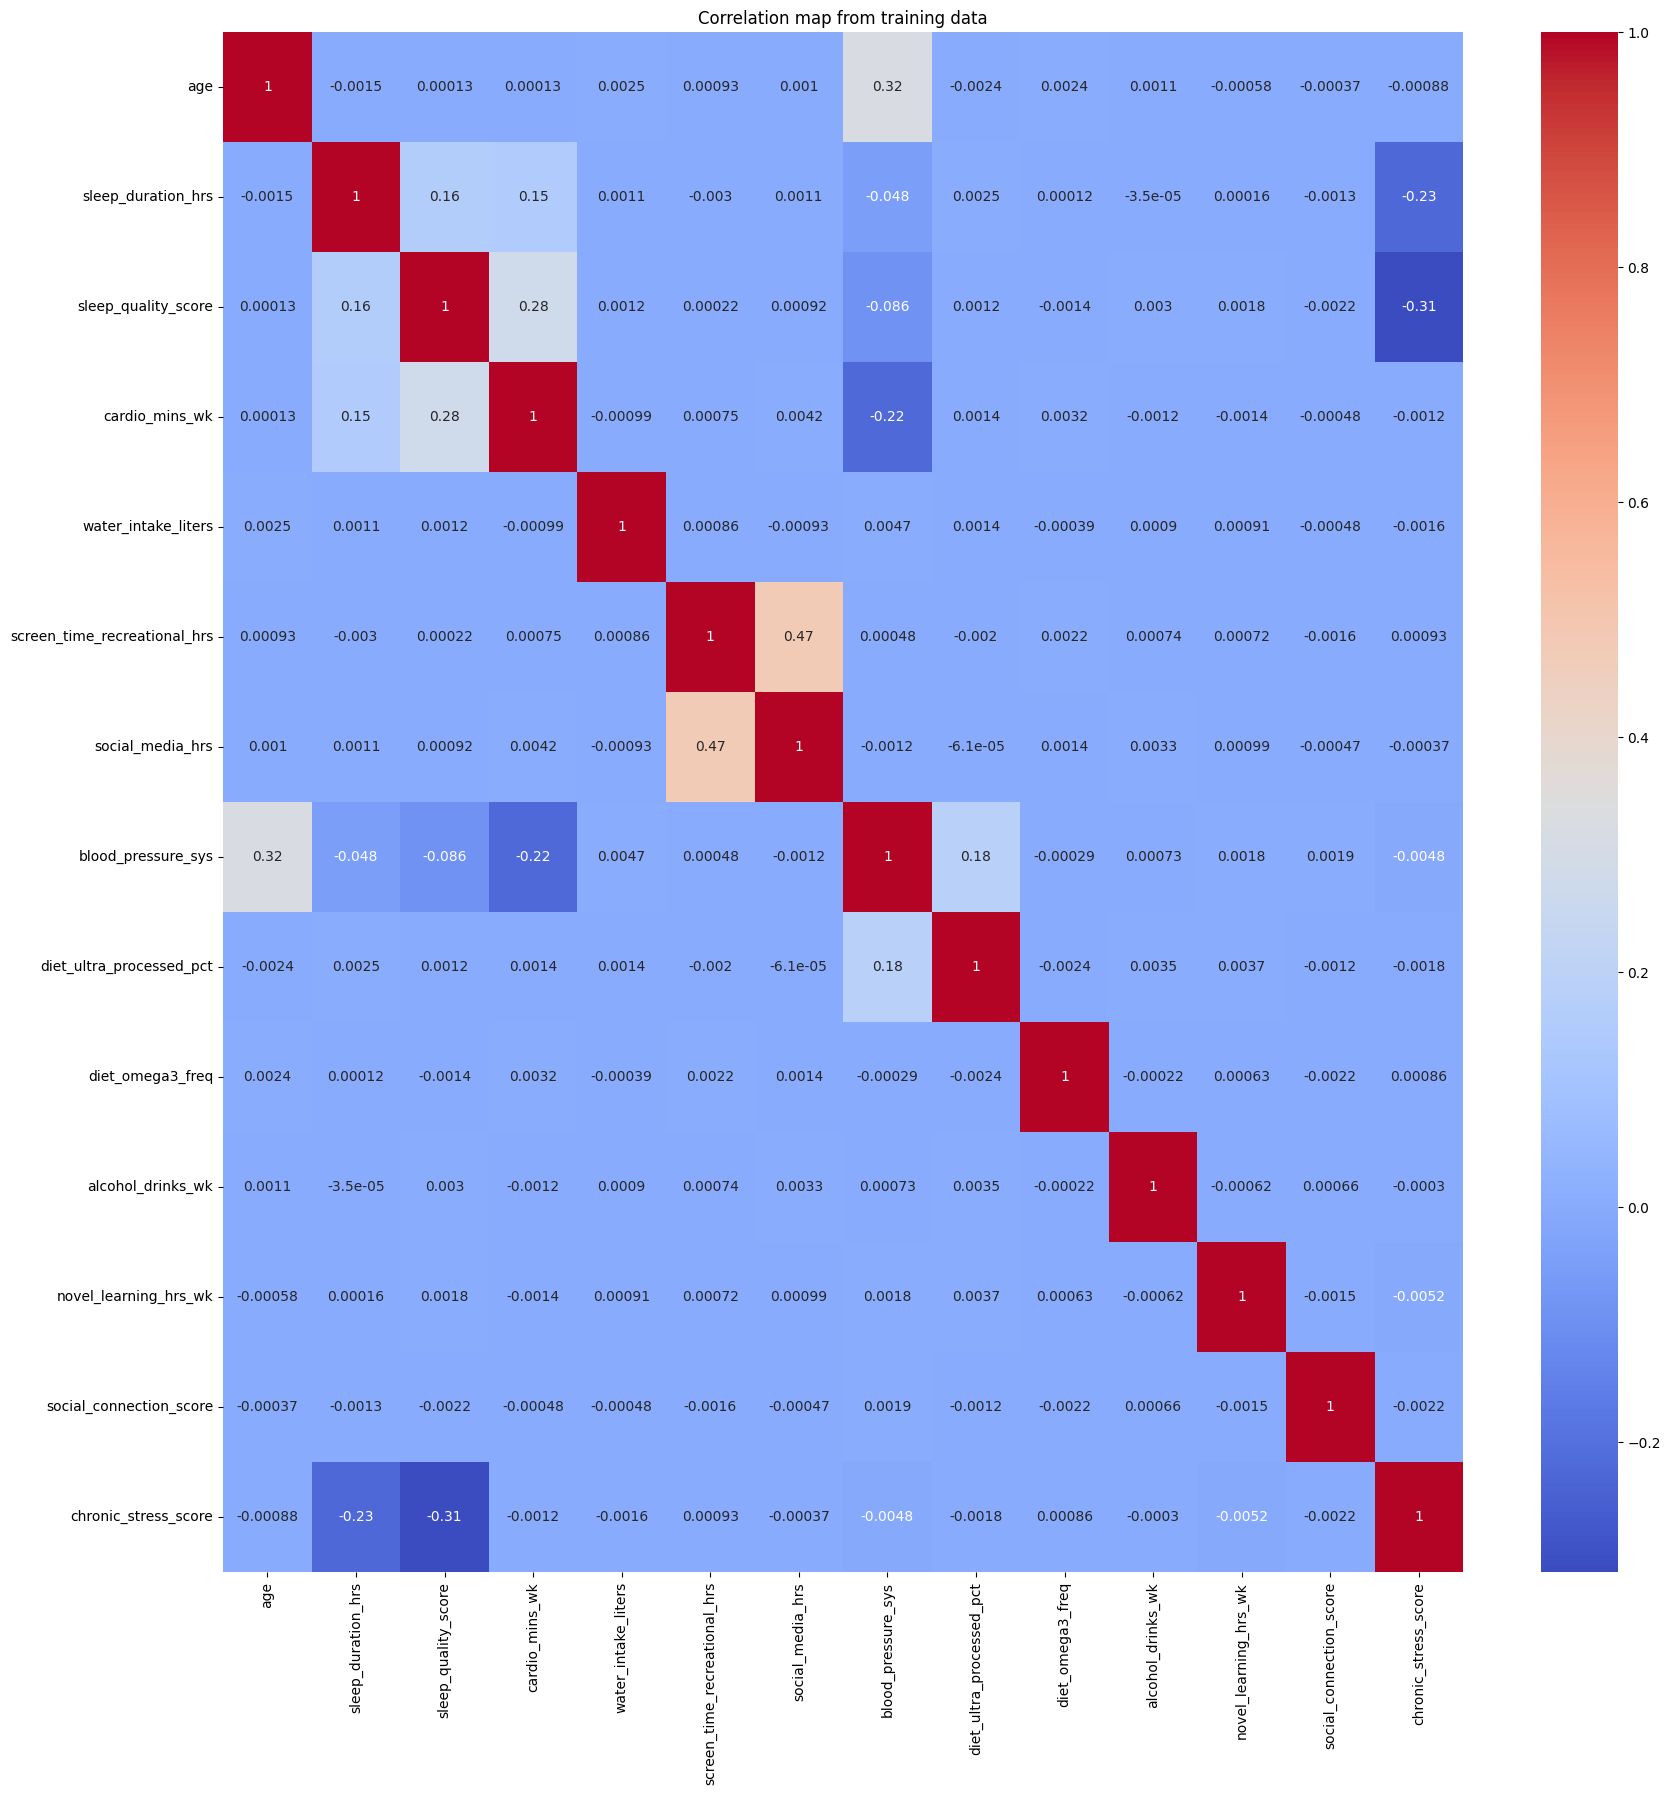

In [132]:
# creating a new dataframe with only numerical features for correlation map and whisker plots
df_numeric = df_train.drop(columns=categorical)

# Drop ID and Target for plotting
df_numeric = df_numeric.drop(columns=['id', 'target'])

# correlation map from numerical features, modified code from lecture 12
plt.figure(figsize=(20,20))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation map from training data")

We drop the missing values here to make the boxplot. In data cleaning, we will handle those values in another way.

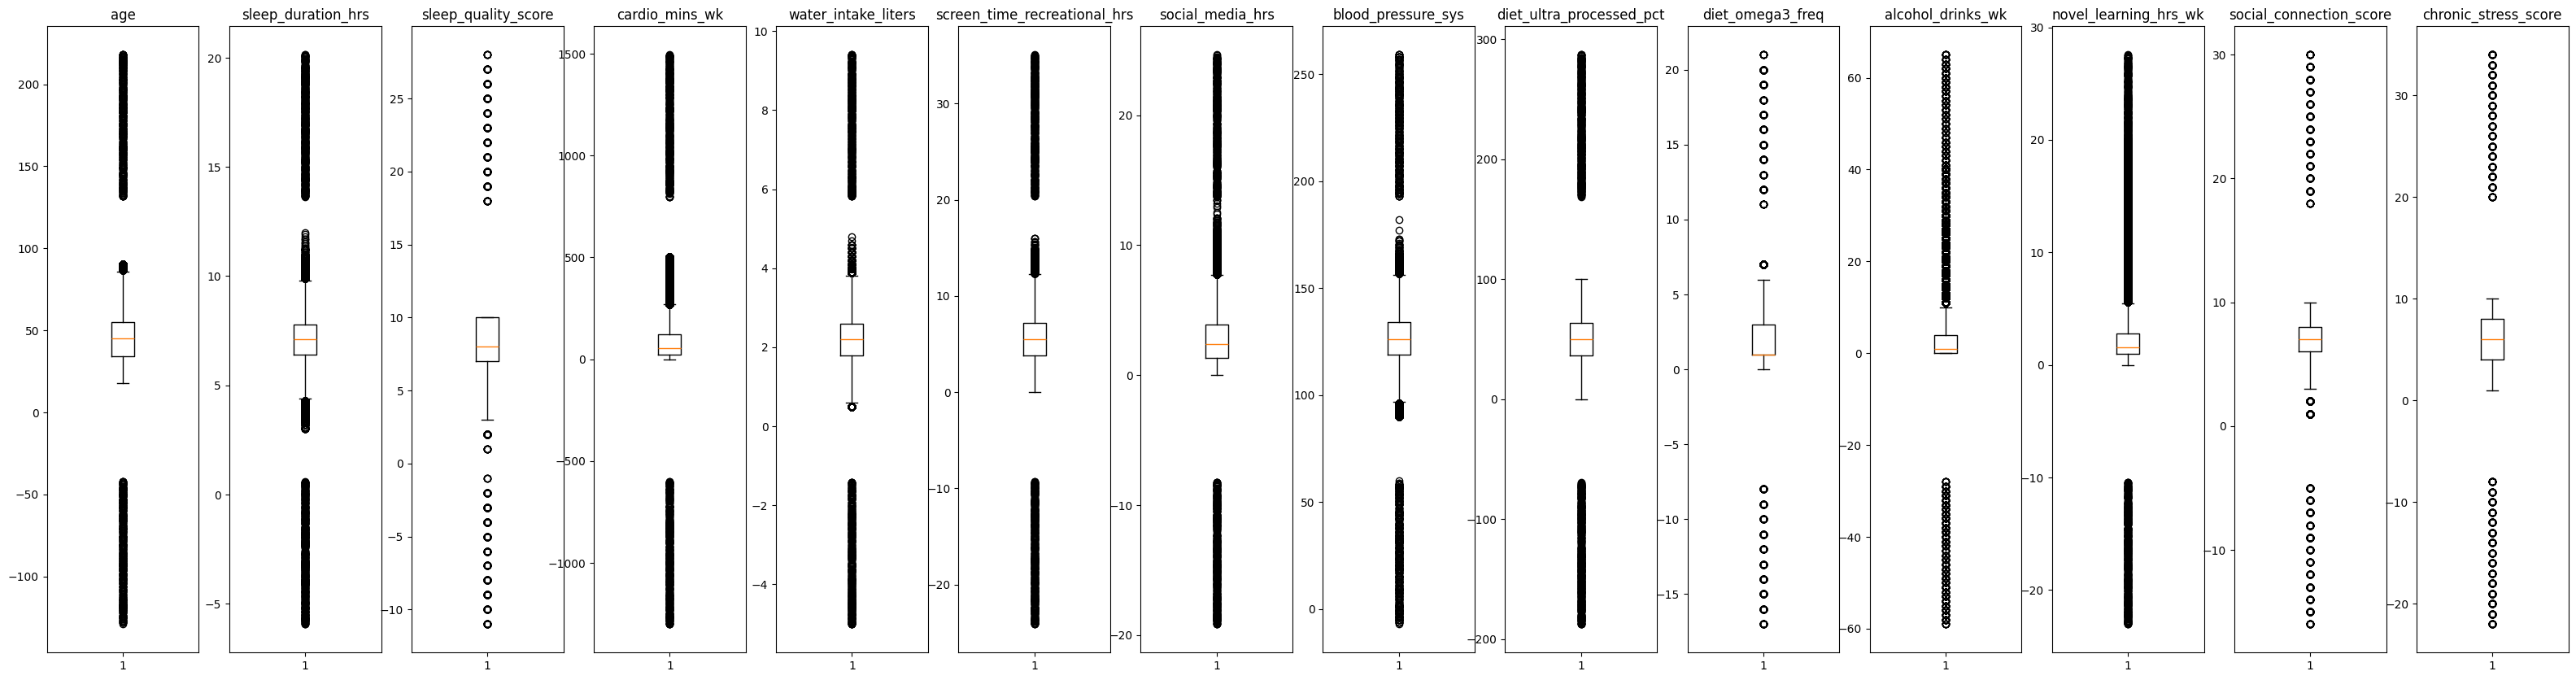

In [133]:
df_numeric = df_numeric.dropna()

# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_numeric.columns), figsize=(40,10))

for i, column in enumerate(df_numeric.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_numeric[column])

In [134]:
totalNegativeValues = 0

# Checking for negative values
for columns in df_numeric.columns:
    invalid = df_numeric[(df_numeric[columns] < 0)]
    print(len(invalid))
    totalNegativeValues += len(invalid)

print("Total below zero values :", totalNegativeValues)
    

433
420
477
413
437
456
452
47
459
455
520
485
464
450
Total below zero values : 5968


Interpreting the results from data exploration we can imply a few things. There are both numerical and categorical features. There are a lot of missing values, as well as some values outside of a valid range. Like ages less than 18 and daily activity above 24 hours? This can be fixed with data cleaning and an imputer. There are not a lot of linearly correlated features.

### Data cleaning and visualisation

First we clean the training set for any values outside of their legal scope, like age less than 18 and sleep more than 24 hours a day. In addition we have self rated scores from 1-10. In case of overshoot / undershoot we can clamp these values. A crybaby saying i have -100 of 10 sleep quality can be treated as 1/10 sleep quality. 

In [135]:
def cleaning(df):
    df = df.copy()
    original_size = len(df)

    # Features that can be clipped between 1-10
    clipped_features  = [
        'sleep_quality_score', 
        'social_connection_score', 
        'chronic_stress_score'
    ]

    # Clip salvageable features
    for col in clipped_features:
        df[col] = df[col].clip(1, 10)


    # Valid range for features 
    feature_ranges = {
        'age': (18, 90), # Specified in data description 
        'sleep_duration_hrs': (0, 24), # Good luck sleeping more than 24 hours a day
        'cardio_mins_wk': (0, 1100), # assume less than 2,6 hours a day 
        'water_intake_liters': (0, 6),
        'screen_time_recreational_hrs': (0, 20), # you need at least 4 hours sleep
        'social_media_hrs': (0, 20), 
        'blood_pressure_sys': (70, 200), 
        'diet_ultra_processed_pct': (0, 100), # percent 0-100
        'diet_omega3_freq': (0, 7),  #  Days per week of consuming brain-healthy foods
        'alcohol_drinks_wk': (0, 60),
        'novel_learning_hrs_wk': (0, 20), # you need at least 4 hours sleep
    }

    # Remove observations outside valid ranges
    for col, (lower, upper) in feature_ranges.items():
        l2 = len(df)

        # Keep NAN values and values inside the value range
        df = df[ df[col].isna() | df[col].between(lower, upper)]
        l1 = len(df)

        print(f"Removed {l2-l1} ({(l2-l1) / original_size:.2%}) rows out of range ({lower}, {upper}) from {col}. ")

    removed = original_size - len(df)

    print(f"Removed {removed} rows ({removed / original_size:.2%})")

    return df

In [136]:
# Read CSV files again in case we lost data during explorations
df_train = pd.read_csv('train.csv')
df_submission = pd.read_csv('test.csv')

df_train = cleaning(df_train)

Removed 1698 (0.46%) rows out of range (18, 90) from age. 
Removed 776 (0.21%) rows out of range (0, 24) from sleep_duration_hrs. 
Removed 1351 (0.37%) rows out of range (0, 1100) from cardio_mins_wk. 
Removed 1709 (0.47%) rows out of range (0, 6) from water_intake_liters. 
Removed 1654 (0.45%) rows out of range (0, 20) from screen_time_recreational_hrs. 
Removed 1267 (0.34%) rows out of range (0, 20) from social_media_hrs. 
Removed 1640 (0.45%) rows out of range (70, 200) from blood_pressure_sys. 
Removed 1712 (0.47%) rows out of range (0, 100) from diet_ultra_processed_pct. 
Removed 1680 (0.46%) rows out of range (0, 7) from diet_omega3_freq. 
Removed 986 (0.27%) rows out of range (0, 60) from alcohol_drinks_wk. 
Removed 1291 (0.35%) rows out of range (0, 20) from novel_learning_hrs_wk. 
Removed 15764 rows (4.29%)


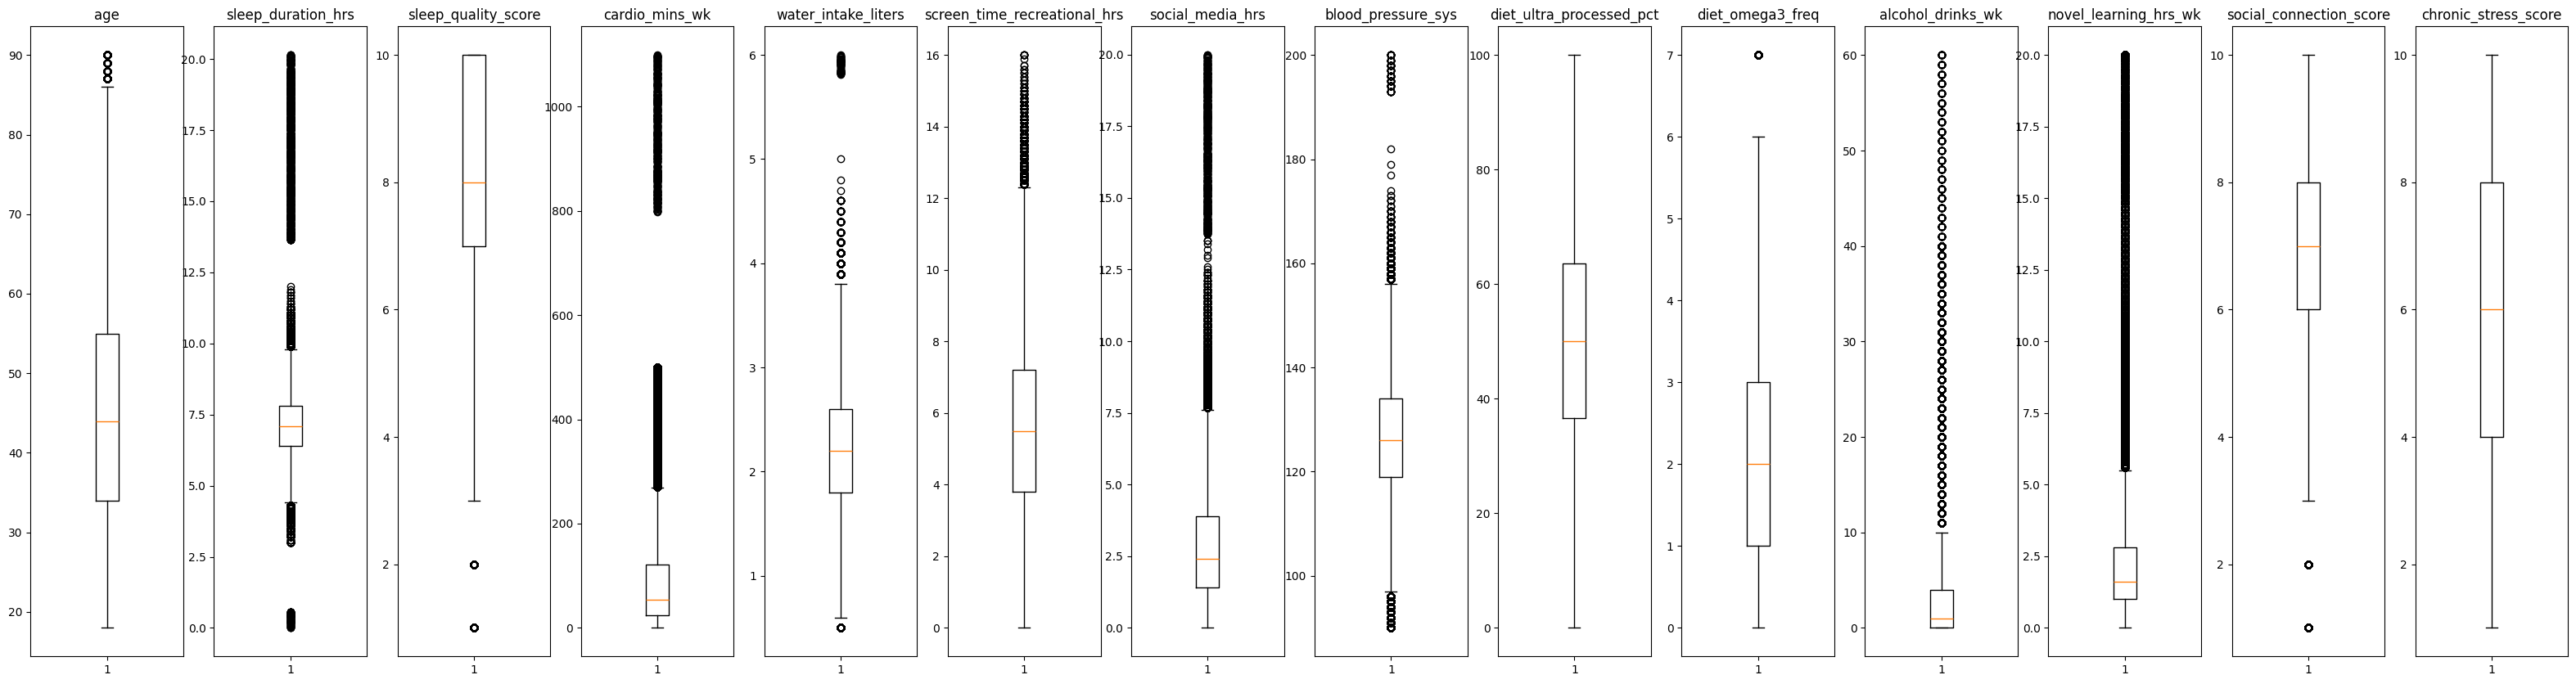

In [137]:

df_visual = df_train.drop(columns=["target", "id", "smoking_status"])

# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_visual.columns), figsize=(40,10))

for i, column in enumerate(df_visual.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_visual[column].dropna())

### Data preprocessing

In [138]:
x_train = df_train.drop(columns=["target", "id"])
y_train = df_train["target"]

X_train, X_test, Y_train, Y_test = train_test_split(
    x_train, 
    y_train, 
    test_size=0.4, 
    random_state=42, 
) 

In [139]:
# Naming the columns with categorical data for preprocessing 
categorical_features = [
    "smoking_status"
]

# Getting the columns with numerical data for preprocessing
numerical_features = []
for col in X_train.columns:
    if col not in categorical_features:
        numerical_features.append(col)


# Numerical preprocessing
numerical_pipeline = Pipeline([
    # We dont have any missing data, but adding imputer for robustness as mentioned in the lecture
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing with no scaling
numerical_pipeline_no_scaling = Pipeline([
    # Some models dont require scaling
    ('imputer', SimpleImputer(strategy='median')),
])

# Polynomial numerical preprocessing
polynomial_numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('polynomial', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    # One hot encoding because we have no ordinal features
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

In [140]:
# Preproccesor
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Preproccesor without scaling
preprocessor_no_scaling = ColumnTransformer([
    ('numerical', numerical_pipeline_no_scaling, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

# Preopocessor for polynomial regressor
polynomial_preprocessor = ColumnTransformer([
    ('numerical', polynomial_numerical_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

### Modelling

In [141]:
# Structures to store a model and its results
results = []
models = {}

def evaluate_regressor(name, grid):
    # Validation predictions
    predictions = grid.predict(X_test)

    # Store results
    result = {
        'Model': name,
        'CV': -grid.best_score_,
        'Validation MAE': mean_absolute_error(Y_test, predictions),
        'Parameters': grid.best_params_
    }

    results.append(result)
    models[name] = grid

    # Log results
    print(f"\n{name}")
    print(f"CV score:         {result['CV']:.4f}")
    print(f"Validation MAE: {result['Validation MAE']:.4f}")
    print(f"Parameters:     {result['Parameters']}")

    return predictions

def evaluate_ensamble(name, grid, predictions):
    # Store results
    result = {
        'Model': name,
        'CV': -grid.best_score_,
        'Validation MAE': mean_absolute_error(Y_test, predictions),
        'Parameters': grid.best_params_
    }

    results.append(result)
    models[name] = grid

    # Log results
    print(f"\n{name}")
    print(f"CV score:         {result['CV']:.4f}")
    print(f"Validation MAE: {result['Validation MAE']:.4f}")
    print(f"Parameters:     {result['Parameters']}")

    return predictions

#### Pipeline A
Simple regression analasys. Here we are testing PCR, polynomial regression, and Ransac, using cross validation

In [142]:
# Cross validation
cv = KFold(n_splits=10, shuffle=True, random_state=42)

In [143]:
# PCR
PCR_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('pca', PCA(svd_solver='full')),
    ('regressor', LinearRegression())
])

PCR_param_grid = {
    'pca__n_components': [0.80, 0.90, 0.95, 0.99]
}

PCR_grid = GridSearchCV(
    PCR_pipeline,
    PCR_param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

PCR_grid.fit(X_train, Y_train)
evaluate_regressor("PCR", PCR_grid)


PCR
CV score:         1.0692
Validation MAE: 1.0675
Parameters:     {'pca__n_components': 0.99}


array([27.20068287, 26.7536983 , 27.8025536 , ..., 28.156463  ,
       27.28471849, 29.5698915 ], shape=(140695,))

In [144]:
POLY_pipeline = Pipeline([
    ('preprocessor', polynomial_preprocessor),
    ('regressor', LinearRegression())
])

POLY_param_grid = {
    'preprocessor__numerical__polynomial__degree': [1, 2, 3]
}

POLY_grid = GridSearchCV(
    POLY_pipeline,
    POLY_param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

POLY_grid.fit(X_train, Y_train)
evaluate_regressor("Poly", POLY_grid)


Poly
CV score:         0.9157
Validation MAE: 0.9138
Parameters:     {'preprocessor__numerical__polynomial__degree': 3}


array([28.06349506, 26.84994671, 28.24337216, ..., 27.75010826,
       27.57096917, 29.02667753], shape=(140695,))

In [145]:
# Ransac
RANSAC_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RANSACRegressor(
        estimator=LinearRegression(),
        random_state=42
    ))
])

RANSAC_param_grid = {
    'regressor__min_samples': [0.5, 0.75, None],
    'regressor__max_trials': [100, 300],
    'regressor__residual_threshold': [None, 2, 3]
}

RANSAC_grid = GridSearchCV(
    RANSAC_pipeline,
    RANSAC_param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

RANSAC_grid.fit(X_train, Y_train)
evaluate_regressor("Ransac", RANSAC_grid)


Ransac
CV score:         1.0330
Validation MAE: 1.0305
Parameters:     {'regressor__max_trials': 300, 'regressor__min_samples': 0.75, 'regressor__residual_threshold': 2}


array([27.41380611, 26.97532317, 28.0404092 , ..., 28.17066593,
       27.3246596 , 28.93346224], shape=(140695,))

#### Pipeline B
Multi-class classification analysis with an ensemble classifier. To this end bin the target variable into discrete chunks and train a classification model on the binned target variable. For binning continuous data (transforming continuous target to discrete target values), you can use pandas.qcut() or pandas.cut().Test and comment on how the number of bins affects the prediction.

Here we are testing randomforest and xgboost over a different number of bins. [1, 5, 10, 20, 25, 30]

In [146]:
# Bins to test
n_bins_list = [1, 5, 10, 20, 25, 30]

In [147]:
# Train random forest classifier on different amount of bins
RF_classifier_pipeline = Pipeline([
    ('preprocessor', preprocessor_no_scaling),
    ('classifier', RandomForestClassifier(random_state=42))
])

RF_param_grid = {
    'classifier__n_estimators': [200],
    'classifier__max_depth': [None, 2, 3],
    'classifier__min_samples_leaf': [1, 3]
}

cv_classifier = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for n_bins in n_bins_list:
    Y_train_binned, bin_edges = pd.qcut(
        Y_train,
        q=n_bins,
        labels=False,
        retbins=True,
        duplicates='drop'
    )

    # Calculate median target value for each bin
    bin_centers = Y_train.groupby(Y_train_binned).median().to_dict()

    RF_grid = GridSearchCV(
        RF_classifier_pipeline,
        RF_param_grid,
        cv=cv_classifier,
        scoring='accuracy', # Fitting the classifier using accuracy, then evaluating it with mean absolute error
        n_jobs=-1
    )

    RF_grid.fit(X_train, Y_train_binned)

    # Test on validation set
    # Predict bins
    predicted_bins = RF_grid.predict(X_test)

    # Convert bins to numerical scores
    RF_predictions = np.array([bin_centers[bin] for bin in predicted_bins])

    # Evaluate
    evaluate_ensamble(f"RF_bins={n_bins}", RF_grid, RF_predictions)



RF_bins=1
CV score:         -1.0000
Validation MAE: 1.4339
Parameters:     {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

RF_bins=5
CV score:         -0.5711
Validation MAE: 1.1270
Parameters:     {'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

RF_bins=10
CV score:         -0.4289
Validation MAE: 0.9055
Parameters:     {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 200}

RF_bins=20
CV score:         -0.4289
Validation MAE: 0.9055
Parameters:     {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 200}

RF_bins=25
CV score:         -0.4127
Validation MAE: 0.8924
Parameters:     {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 200}

RF_bins=30
CV score:         -0.4127
Validation MAE: 0.8924
Parameters:     {'classifier__max_depth': None, 'classif

In [148]:
# Train XGBclassifier on different amount of bins
XGB_classifier_pipeline = Pipeline([
    ('preprocessor', preprocessor_no_scaling),
    ('classifier', XGBClassifier(random_state=42))
])

XGB_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__gamma': [0, 3],
    'classifier__reg_lambda': [1, 5],
}

cv_classifier = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for n_bins in n_bins_list:
    Y_train_binned, bin_edges = pd.qcut(
        Y_train,
        q=n_bins,
        labels=False,
        retbins=True,
        duplicates='drop'
    )

    # Calculate median target value for each bin
    bin_centers = Y_train.groupby(Y_train_binned).median().to_dict()

    XGB_grid = GridSearchCV(
        XGB_classifier_pipeline,
        XGB_param_grid,
        cv=cv_classifier,
        scoring='accuracy', # Fitting the classifier using accuracy, then evaluating it with mean absolute error
        n_jobs=-1
    )

    XGB_grid.fit(X_train, Y_train_binned)

    # Predict bins and assign values
    predicted_bins = XGB_grid.predict(X_test)
    XGB_predictions = np.array([bin_centers[bin] for bin in predicted_bins])

    # Evaluate
    evaluate_ensamble(f"XGB_bins={n_bins}", XGB_grid, XGB_predictions)



XGB_bins=1
CV score:         -1.0000
Validation MAE: 1.4339
Parameters:     {'classifier__gamma': 0, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__reg_lambda': 1}

XGB_bins=5
CV score:         -0.5593
Validation MAE: 1.1532
Parameters:     {'classifier__gamma': 3, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__reg_lambda': 1}

XGB_bins=10
CV score:         -0.4143
Validation MAE: 0.9156
Parameters:     {'classifier__gamma': 0, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__reg_lambda': 5}

XGB_bins=20
CV score:         -0.4143
Validation MAE: 0.9156
Parameters:     {'classifier__gamma': 0, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__reg_lambda': 5}

XGB_bins=25
CV score:         -0.3967
Validation MAE: 0.9010
Parameters:     {'classifier__gamma': 3, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__reg_lambda': 5}

XGB_bins=30
CV score:         -0.396

### Final evaluation

In [157]:
df_results = pd.DataFrame(results)
df_results = df_results.sort_values('Validation MAE')


In [158]:
df_results

,Model,CV,Validation MAE,Parameters
7,RF_bins=25,-0.412702,0.892391,"{'classifier__max_depth': None, 'classifier__m..."
8,RF_bins=30,-0.412702,0.892391,"{'classifier__max_depth': None, 'classifier__m..."
13,XGB_bins=25,-0.396653,0.900999,"{'classifier__gamma': 3, 'classifier__max_dept..."
14,XGB_bins=30,-0.396653,0.900999,"{'classifier__gamma': 3, 'classifier__max_dept..."
6,RF_bins=20,-0.428869,0.905533,"{'classifier__max_depth': None, 'classifier__m..."
5,RF_bins=10,-0.428869,0.905533,"{'classifier__max_depth': None, 'classifier__m..."
1,Poly,0.915723,0.913766,{'preprocessor__numerical__polynomial__degree'...
11,XGB_bins=10,-0.414284,0.915598,"{'classifier__gamma': 0, 'classifier__max_dept..."
12,XGB_bins=20,-0.414284,0.915598,"{'classifier__gamma': 0, 'classifier__max_dept..."
2,Ransac,1.032995,1.030490,"{'regressor__max_trials': 300, 'regressor__min..."


It appears having many bins doesnt necessarily mean a model will perform better. More bins appears to give a smaller error, but it seems to peak somewhere at 25 bins, before the error starts to rise again. In our results Random forest performed better with 25 bins over 30

### Select and create final model

In [161]:
# Select the top model from the results dataframe
best_model_name = df_results.iloc[0]["Model"]
print("Best model was: ", best_model_name)

# Get the model grid from trained models dictionary 
best_model = models[best_model_name].best_estimator_



Best model was:  RF_bins=25


In [ ]:
best_model_params = df_results.iloc[0]["Parameters"]

In [ ]:
# Parameters for selecting a model from pipeline B
binned_model = True
n_bins_final = 25

# Train binnded model on all available data
if binned_model:
     # Recreate target bins using all available training data
    y_full_binned = pd.qcut(
        y_train,
        q=n_bins_final,
        labels=False,
        duplicates='drop'
    )
    # Calculate new bin medians
    final_bin_centers = y_train.groupby(y_full_binned).median().to_dict()

    # Train on all available data
    best_model.fit(x_train, y_full_binned)

# Train regression model on all available data
else:
    best_model.fit(x_train, y_train)



### Kaggle submission

In [163]:
# Get submission data and participant ID
participantIds = df_submission['id']
x_input = df_submission.drop(['id'], axis=1)

# Predict targets
y_pred = best_model.predict(x_input)

# Only for pipeline B
if binned_model:
    # Map values from binned models to the bin median
    y_pred = np.array([final_bin_centers[bin] for bin in y_pred]) 


# Clip predictions
y_pred = np.clip(y_pred, 0, 30)

# create submission dataframe and save as CSV file
submission = pd.DataFrame({
    "id": participantIds,
    "target": y_pred
})
submission.to_csv("submissionCA5.csv", index=False)
